# 1) Generation of random variables

Course program (30H / 10 séances de cours de 3h)
1. generation of random variables
2. integration by montecarlo methods
3. montecarlo methods for markov chains

Controles:
- 1.30h le 14 janvier, à la fin du chapitre 2 (contenu jusqu'à vacances)
- 2/2.30h le 8 fevrier

Note finale:
0.4 C1 + 0.6 C2

Pas de documents, calculatrice type collége

# Inversion method:

## TD1, ex. 1 : variable continue

Soit $x$ une v.a. de loi de Weibull:

$$
f(x)=\theta x^{\theta -1} e^{-x^{\theta}},
$$

si $x>0$ et $f(x)=0$ sinon.


- Fonction de repartition, obtenu en integrand la loi:
$$
F(t) = P(X \leq t) = \left[ -e^{x^{\theta}} \right]_{0}^{t} = -e^{- t^{\theta}} +1 \quad \in \quad ]0,1[
$$
pour $t>0$ et $F(x)=0$ pour $t<=0$.

- F est bijective de $[0,+\infty]$ dans $]0,1[$, donc l'inverse générailsée $F^{-1}$ est égale à la fonction récriproque de $F$ restreinte sur $]0,+\infty[$.

Soit $u \in]0,1[$ et $t>0$, on obtient
$$
u = 1- e^{-t^{\theta}} \iff 1- u = e^{-t^{\theta}} \iff t^{\theta} = - ln(1-u) \iff t = \left(- ln(1-u) \right)^{\frac{1}{\theta}},
$$
d'où l'inverse généralisée est
$$
F^{-1}(u) = \left(- ln(1-u) \right)^{\frac{1}{\theta}}.
$$

- Par la méthode d'inversion, soit $U \sim \mathcal{U}(]0,1[)$, alors $F^{-1}(u) = \left(- ln(1-u) \right)^{\frac{1}{\theta}}$ est de loi de Weibull de paramétre $\theta$.

In [1]:
n <- 5000                         # nombre observations
theta <- 2                        # paramétre

set.seed(155)                     # seed
T1s <- Sys.time()                 # time

u <- runif(n)                         # U UNIFORME
vect_obs <- (-log(1-u))^(1/theta)     # LOI X \sim F^{-1}(U)

T2s <- Sys.time()
difftime(T2s,T1s)

Time difference of 0.00366497 secs

Histogramme de la loi de $X \sim F^{-1}(U)$ tracer par la méthode d'inversion:

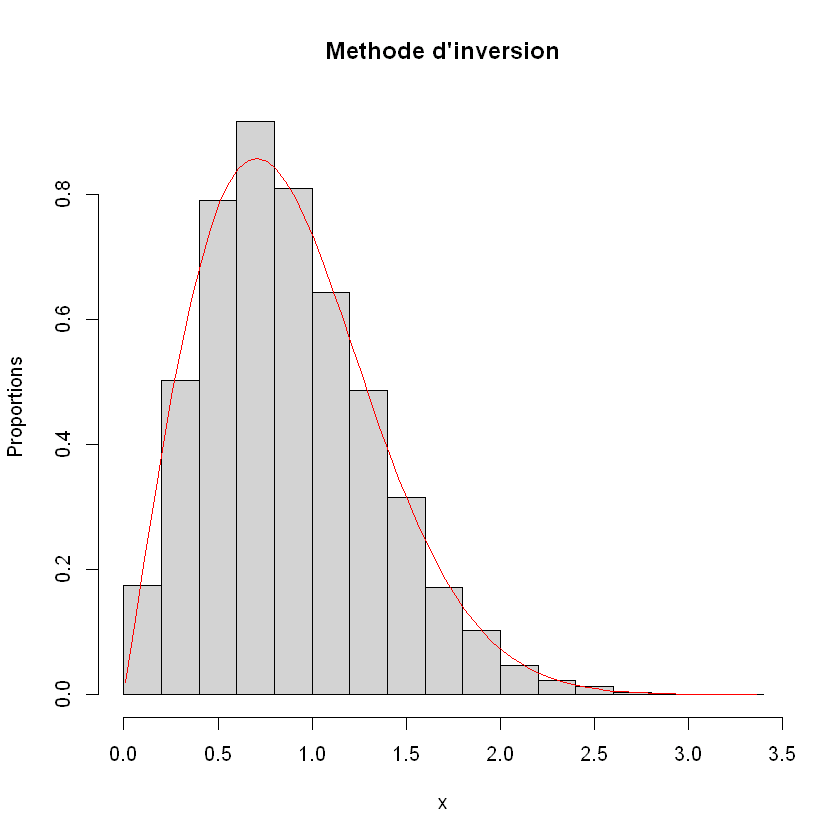

In [2]:
hist(vect_obs,freq=FALSE,  main="Methode d'inversion", xlab="x", ylab="Proportions")   # freq: pour normaliser   

xl <- seq(0.01, max(vect_obs), by=0.05)

lines(xl, theta*xl^{theta-1}*exp(-xl^{theta}), col="red")

Histogramme de la loi de $X$ exacte:

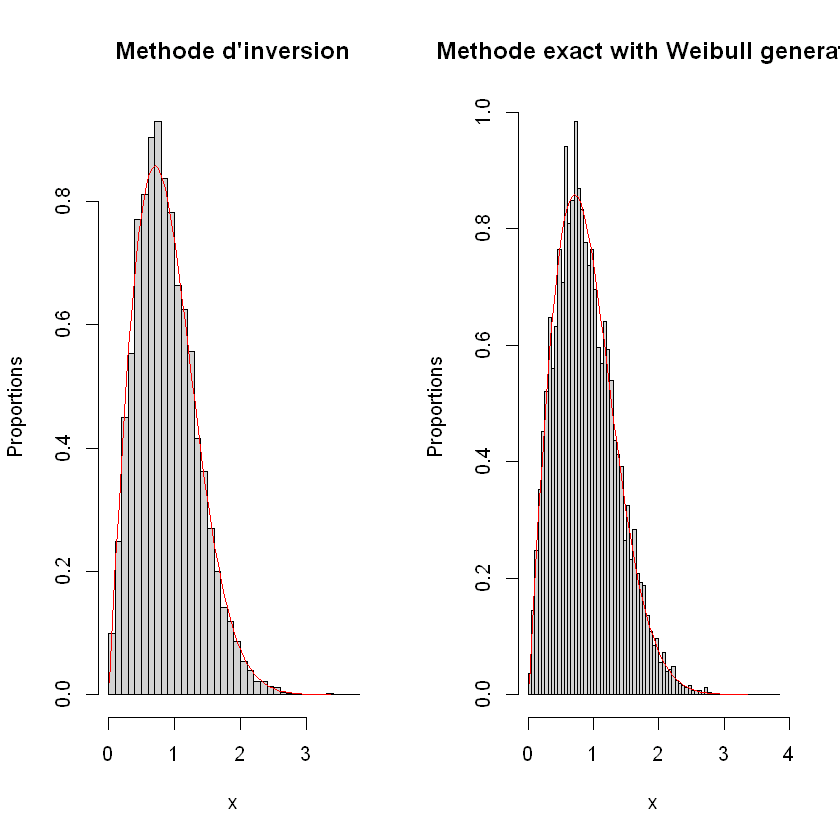

In [3]:
par(mfrow=c(1,2))
hist(vect_obs, freq=FALSE, main="Methode d'inversion", xlab="x", ylab="Proportions", breaks=seq(0, max(vect_obs)+0.5, by=0.1))
xl <- seq(0.01, max(vect_obs), by=0.05)
lines(xl, theta*xl^{theta-1}*exp(-xl^{theta}), col="red")

hist(rweibull(n, theta), freq=FALSE, main="Methode exact with Weibull generator", xlab="x", ylab="Proportions", breaks=seq(0, max(vect_obs)+0.5, by=0.05)) 
lines(xl, dweibull(xl, theta), col="red")

## TD1, ex.2 : variable discréte

Soit $X$ une v.a. de loi
$$
- P(X=1)=0.25 \quad
- P(X=2)=0.5 \quad
- P(X=3)=0.125 \quad
- P(X=4)= 0.125 \quad.
$$

Donc, la fonction de répartition est:
$$
F_{X}(t) = P(X \leq t) = \begin{cases}
0 & si \quad t<1 \\
0.25 & si \quad 1\leq t \leq 2 \\
0.75 & si \quad 2\leq t \leq 3 \\
0.875 & si \quad 3\leq t \leq 4 \\
1 & si \quad t \geq 4 \\
\end{cases}
$$

L'inverse géneralisée est
$$
F_{X}^{-1}(u) = \begin{cases}
1 & si \quad u \in]0,0.25[ \\
2 & si \quad u \in]0.25, 0.75[ \\
3 & si \quad u \in]0.75, 0.875[ \\
4 & si \quad u \in]0.875, 1[ \\
\end{cases}
$$

In [7]:
n <- 3000  # observations

u <- runif(n)      # LOI UNIFORME

x_obs <- numeric(n)

for (i in 1:n) {

  if (u[i] <= 0.25) { x_obs[i] <- 1 }
  
  else if (u[i] <= 0.75) { x_obs[i] <- 2 }
  
  else if (u[i] <= 0.875) { x_obs[i] <- 3 } 
  
  else { x_obs[i] <- 4 }
}

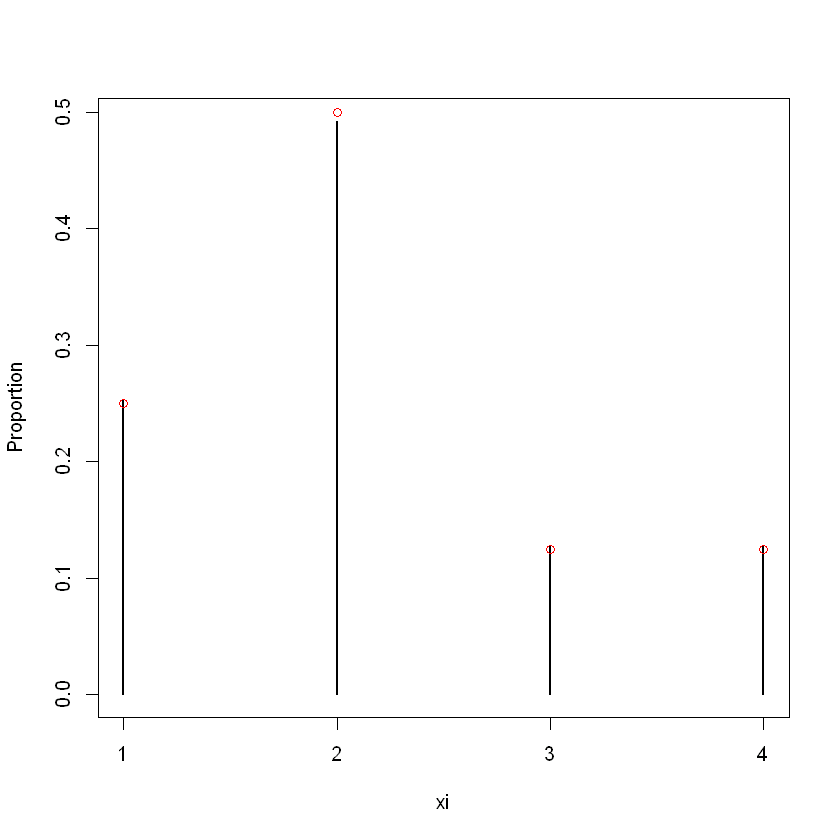

In [13]:
n <- 3000

probasX <- c(0.25, 0.5, 1/8, 1/8)    # p=(p1,p2,p3,p4)
qprob0 <- c(0, cumsum(probasX))      # somme cumulative, q = c(0, 0.25, 0.75, 0.875, 1)

x_obs <- numeric(n)                  # stock observations

u <- runif(n)                        # LOI UNIFORME

for (i in 1:n) {

    x_obs[i] <- sum(qprob0 < u[i])        # rajoute à x_obs: somme les indices qui correspondent à "q < u[i]",
                                          #                  donc rajoute la position pour laquelle < u[i]
}

plot(table(x_obs)/n, type="h", xlab="xi", ylab="Proportion")        # h: batons

points(1:4, probasX, col="red")                                   # rajoute les points (k, pk)


## TD1, ex. 3

We found that

$$
limmin = \max(0, \lambda - 4 \sqrt{\lambda}), \quad limmax = \lambda + 4 \sqrt{\lambda} .
$$

In [ ]:
SimuP <- function(n, lambda) {

    # limmin
    ecart <- 4*sqrt(lambda)
    val <- (max(0, ceiling(lambda - ecart))):(floor(lambda+ecart))

    # loi de X
    qprob <- ppois(val, lambda)
    qprob0 <- c(0, qprob)

    u <- runif(n) 
    u <- u[ u<=max(qprob) ]
    
    l <- length(u)
    x_obs <- numeric(l)
    # inversion method
    for (i in 1:l) {
        x_obs[i] <- val[ sum(qprob0 < u[i])]
    }

    return(x_obs)
}

Simulation for $\lambda=20$.

In [29]:
n <- 1000
lambda <- 20
system.time(x_pois20 <- SimuP(n, 20))

   utente   sistema trascorso 
     0.03      0.00      0.02 

In [30]:
ecart <- 4*sqrt(lambda)
bmin <- max(0, ceiling(lambda-ecart))
bmax <- floor(lambda+ecart)
system.time(xbis <- rpois(n, lambda))

   utente   sistema trascorso 
        0         0         0 

In [31]:
bmin

[1] 3

In [32]:
bmax

[1] 37

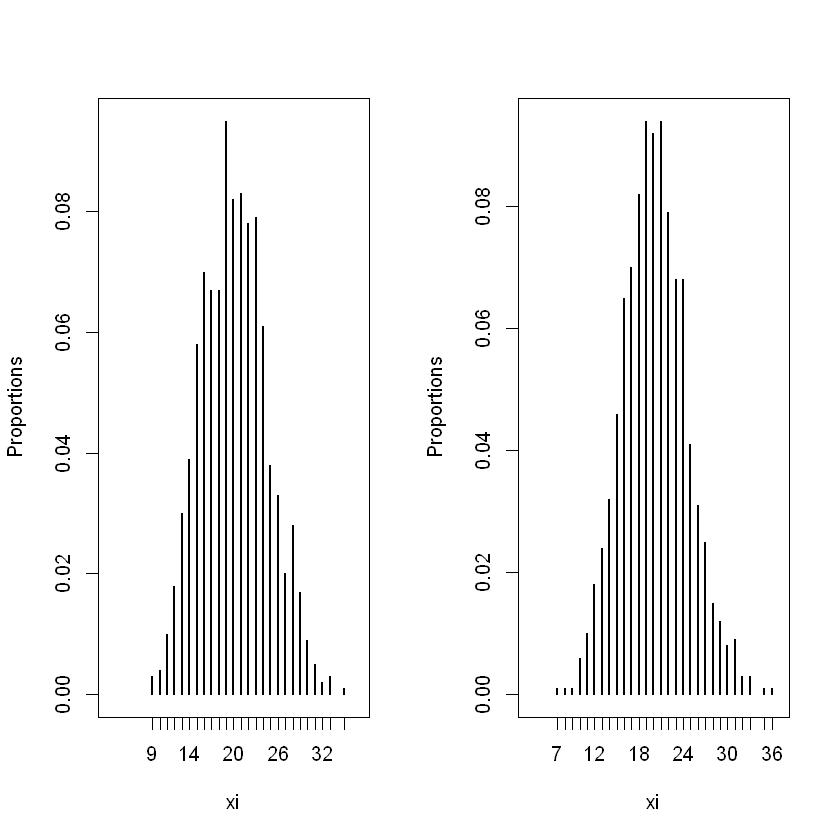

In [34]:
binf <- min(bmin, min(xbis))
bsup <- max(bmax, max(xbis))

val_aut <- binf:bsup
par(mfrow=c(1,2))
plot(table(x_pois20)/n, type="h", xlim=c(binf, bsup), xlab="xi", ylab="Proportions")

plot(table(xbis)/n, type="h", xlim=c(binf, bsup), xlab="xi", ylab="Proportions")


# Rejection method

### TD 1, EX 5

Soit $X$ de loi
$$
f(x) = \sqrt{\left(\dfrac{2}{\pi}\right)} \exp\left(-\dfrac{x^2}{2}\right) \mathbb{1}\{x\geq 0\}
$$.

The instrumental law is $g\sim Exp(\lambda)$, so of density
$$
g(x) = \lambda \exp^{-\lambda x}.
$$

We observe that for all $\lambda > 0$:
$$
\dfrac{f(x)}{g(x)} = \dfrac{ \sqrt{\frac{2}{\pi}} \exp\left(-\frac{x^2}{2} \right)}{ \lambda \exp^{-\lambda x}} = \sqrt{\dfrac{2}{\pi}} \dfrac{1}{\lambda} \exp\left( -\dfrac{x^2}{2} + \lambda x \right).
$$

Because $\exp$ is bijective and incresing, maximizing $\frac{f(x)}{g(x)}$ corresponds to maximize the function
$$
x \to h(x) = - \dfrac{x^2}{2} + \lambda x, \quad \forall x \geq 0.
$$

The derivative is $h'(x)=-x+\lambda$ which is zero at $x=\lambda$. Therefore, the function $h(x)$ is maximized for $\lambda=x$ and
$$
h(\lambda) = -\dfrac{\lambda^2}{2} + \lambda^2 = \dfrac{\lambda^2}{2}.
$$

We conclude that $\forall x\geq 0$:
$$
\dfrac{f(x)}{g(x)} \leq \sqrt{\dfrac{2}{\pi}} \dfrac{1}{\pi} \exp\left(\dfrac{\lambda^2}{2}\right) =: c_{\lambda} \iff f(x) \leq c_{\lambda} g(x)
$$

We look for the smallest possible $c_{\lambda}$, which minimizes the computational time. Therefore, we call the part depending on $\lambda$ as
$$
c(\lambda):=\dfrac{ \exp\left(\dfrac{x^2}{2}\right) }{ \lambda }.
$$

After computing the derivative, it is minimized for $\lambda = 1$.

Therefore, the *best* $c_{\lambda}$ is given by
$$
m = c_{1} = \sqrt\dfrac{2}{\pi} \exp^{\frac{1}{2}} \approx 1.316 .
$$

In [16]:
m <- sqrt(2/pi)*exp(1/2)

print(m)

[1] 1.315489


Call
$$
\alpha(y) = \dfrac{f(y)}{m g_{1}(y)} = \exp\left(\dfrac{-y^2}{2} + y - \dfrac{1}{2}\right) = \exp\left( -(y-1)^2/2 \right) \in [0,1].
$$

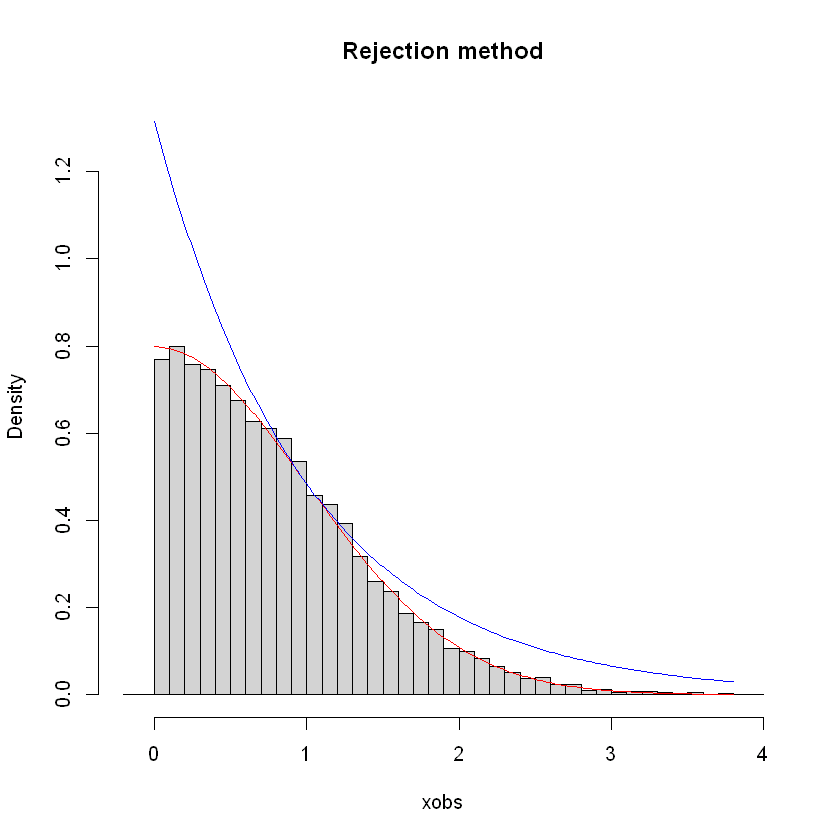

In [25]:
nsimu <- 10000                        # observations
xobs <- numeric(nsimu)
compt <- 0

for (i in 1:nsimu) {

    u <- runif(1)
    y <- rexp(1)                      # INSTRUMENTAL DENSITY
    compt <- compt + 1

    while (u > exp(-(y-1)^2/2)) {     # ALPHA(y)

        u <- runif(1)
        y <- rexp(1)                  # INSTRUMENTAL DENSITY
        compt <- compt + 1
    }

    xobs[i] <- y
}

# histogram of observations
hist(xobs, freq=FALSE, main="Rejection method", ylim=c(0, m), breaks=seq(min(xobs)-0.2, max(xobs)+0.2, by=0.1))

xl <- seq(0, max(xobs), by=0.02)

# true density of f
lines(xl, sqrt(2/pi)*exp(-xl^2/2), col="red")

# density of m*g
lines(xl, m*dexp(xl), col="blue")

In [26]:
compt

[1] 13131

### TD 1, EX 6

In [ ]:
nsimu <- 10000                        # observations
xobs <- numeric(nsimu)
compt <- 0

h0 <- 5^5/6^6                         # h(1/6), 

for (i in 1:nsimu) {

    u <- runif(1)
    y <- runif(1)                     # INSTRUMENTAL DENSITY
    compt <- compt + 1

    while (u > h(y)/h(1/6)) {     # ALPHA(y)

        u <- runif(1)
        y <- runif(1)                  # INSTRUMENTAL DENSITY
        compt <- compt + 1
    }

    xobs[i] <- y
}

# histogram of observations
hist(xobs, freq=FALSE, main="Rejection method", ylim=c(0, m), breaks=seq(min(xobs)-0.2, max(xobs)+0.2, by=0.1))

xl <- seq(0, max(xobs), by=0.02)

# true density of f
lines(xl, sqrt(2/pi)*exp(-xl^2/2), col="red")

# density of m*g
lines(xl, m*dexp(xl), col="blue")